# Упражнения по Boosting and Stacking

![Boosting.png](Assets/Boosting.png)

# Цели обучения

- Объяснить, как алгоритм бустинга помогает снизить дисперсию и систематическую ошибку.

## Введение

Мы будем использовать базу данных [«Распознавание действий человека с помощью смартфонов»](https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones), сформированную на основе записей участников исследования, выполнявших повседневные действия (ADL) с смартфоном, оснащенным встроенными инерционными датчиками. Цель состоит в классификации действий по одному из шести видов (ходьба, подъем по лестнице, спуск по лестнице, сидение, стояние и лежание).

Для каждой записи в наборе данных предоставляются следующие данные:

- Трехосное ускорение, полученное с акселерометра (общее ускорение), и расчетное ускорение тела.
- Трехосевая угловая скорость, полученная с гироскопа.
- Вектор из 561 признака с переменными во временной и частотной областях.
- Метка вида деятельности.

Более подробная информация о признаках доступна на указанном выше веб-сайте.

In [2]:
from __future__ import print_function
import os
data_path = [ 'data']

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegressionCV
from sklearn.ensemble import VotingClassifier

from sklearnex import patch_sklearn
patch_sklearn()

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

* Импортируйте данные из файла `Human_Activity_Recognition_Using_Smartphones_Data.csv` и проанализируйте структуру и типы данных. Типов данных будет слишком много, чтобы перечислять их по каждому столбцу отдельно. Вместо этого сгруппируйте типы по количеству.
* Определите, требуется ли масштабирование столбцов с числами типа float.

In [4]:
import pandas as pd

# 1. Импорт данных
# Предполагается, что data_path — это путь к папке с файлом, 
# как указано на вашем скриншоте.
filepath = os.sep.join(data_path + ['Human_Activity_Recognition_Using_Smartphones_Data.csv'])
data = pd.read_csv(filepath, sep=',')

# 2. Анализ структуры и группировка типов данных по количеству
type_counts = data.dtypes.value_counts()
print("Количество столбцов по типам данных:")
print(type_counts)

# Альтернативный и более наглядный вариант через DataFrame:
print("\nСводка по типам:")
print(data.dtypes.value_counts().reset_index().rename(
    columns={'index': 'Тип данных', 0: 'Количество столбцов'}
))

# 3. Проверка диапазона значений для float-столбцов
float_cols = data.select_dtypes(include=['float64']).columns
min_val = data[float_cols].min().min()
max_val = data[float_cols].max().max()
print(f"\nМинимальное значение float-признаков: {min_val}")
print(f"Максимальное значение float-признаков: {max_val}")

Количество столбцов по типам данных:
float64    561
str          1
Name: count, dtype: int64

Сводка по типам:
  Тип данных  count
0    float64    561
1        str      1

Минимальное значение float-признаков: -1.0
Максимальное значение float-признаков: 1.0


В наборе данных довольно много столбцов с предикторами.

И все они — значения типа float. Единственное значение, не относящееся к типу float, — это столбец «categories», который и является объектом прогнозирования.

Минимальное и максимальное значения для столбцов типа float составляют -1,0 и 1,0 соответственно. Однако для методов, основанных на дереве, масштабирование никогда не требуется.

## Вопрос 2

* Присвойте действиям целочисленные коды.
* Разделите данные на обучающий и тестовый наборы. Решите, будет ли производиться стратификация данных при разделении на обучающий и тестовый наборы или нет.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. Присвоение целочисленных кодов действиям
# Название целевого столбца в вашем датасете — 'Activity' 
# (если у вас он называется иначе, замените на нужное имя).
le = LabelEncoder()
data['Activity_encoded'] = le.fit_transform(data['Activity'])

# Посмотрим на соответствие кодов и классов
print("Соответствие классов и кодов:")
for class_name, code in zip(le.classes_, range(len(le.classes_))):
    print(f"{code}: {class_name}")

# 2. Разделение на признаки (X) и целевую переменную (y)
X = data.drop(columns=['Activity', 'Activity_encoded']) # Удаляем текстовый и закодированный таргеты
y = data['Activity_encoded']

# 3. Разделение на train и test с стратификацией
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,       # 20% данных уйдет в тест
    random_state=42,     # Фиксируем seed для воспроизводимости
    stratify=y           # Включаем стратификацию
)

print(f"\nРазмер обучающей выборки: {X_train.shape[0]} строк")
print(f"Размер тестовой выборки: {X_test.shape[0]} строк")

Соответствие классов и кодов:
0: LAYING
1: SITTING
2: STANDING
3: WALKING
4: WALKING_DOWNSTAIRS
5: WALKING_UPSTAIRS

Размер обучающей выборки: 8239 строк
Размер тестовой выборки: 2060 строк


C:\Users\user\AppData\Local\Temp\ipykernel_15240\3983329620.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data['Activity_encoded'] = le.fit_transform(data['Activity'])


**ПРИМЕЧАНИЕ**: Мы собираемся создать обучающий и тестовый наборы данных из `data`. На этих наборах данных мы будем проводить поиск по сетке с различными значениями параметров. Это может занять некоторое время. Чтобы сократить время поиска по сетке, вы можете уменьшить разрешение `data` и создать `X_train, X_test, y_train, y_test` на основе набора данных с уменьшенным разрешением.

Теперь разделите данные на обучающий и тестовый наборы. Здесь не использовалось стратифицированное деление. Если возникнут проблемы с какими-либо метриками ошибок на тестовом наборе, может быть целесообразно начать подбор модели с использованием стратифицированного деления. Однако метод бустинга является довольно мощной моделью, поэтому в данном случае это может оказаться ненужным.

## Вопрос 3

* Постройте модели градиентного бустинга с деревьями, установив все параметры по умолчанию, для следующих значений количества деревьев (`n_estimators = [25, 50, 100, 200, 400]`) и оцените точность на тестовых данных для каждой из этих моделей.
* Постройте график зависимости точности от количества оценок.

**Примечание:** Выполнение этого задания может занять некоторое время в зависимости от количества различных значений, подбираемых для оценок. Установка параметра `max_features=4` в классификаторе градиентного бустинга увеличит скорость сходимости.

Кроме того, это задание аналогично заданию 3 из 9-й недели, за исключением того, что для моделей с бустингом не существует такого понятия, как «ошибка out-of-bag». Кроме того, в модели градиентного бустинга присутствует ошибка в настройке `warm_flag=True`, поэтому не используйте её. Просто создайте модель внутри цикла `for` и задайте количество оценок в этот момент. Это приведёт к тому, что подбор модели займёт немного больше времени. Кроме того, подбор моделей бустинга, как правило, занимает больше времени, чем подбор моделей методом bagging, поскольку «решающие пеньки» необходимо подбирать последовательно.

Начинаем обучение моделей градиентного бустинга...
n_estimators =  25 | Accuracy = 0.9228 | Время: 1.72 сек
n_estimators =  50 | Accuracy = 0.9524 | Время: 3.29 сек
n_estimators = 100 | Accuracy = 0.9782 | Время: 6.54 сек
n_estimators = 200 | Accuracy = 0.9859 | Время: 12.94 сек
n_estimators = 400 | Accuracy = 0.9937 | Время: 26.37 сек


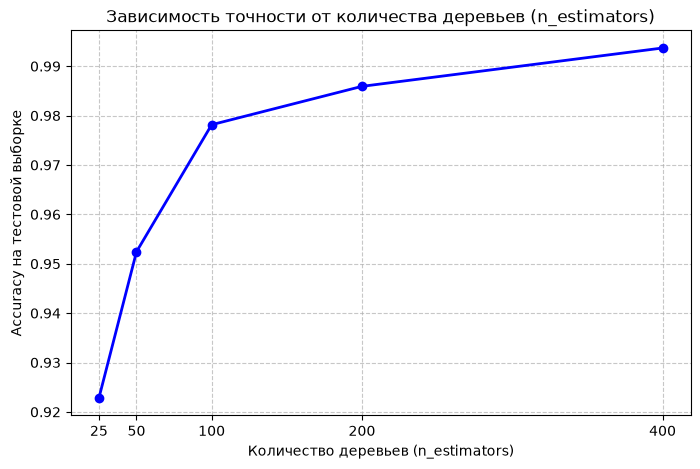

In [6]:
import time
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# Список количеств деревьев (оценок)
n_estimators_list = [25, 50, 100, 200, 400]
accuracies = []
times = []

print("Начинаем обучение моделей градиентного бустинга...")

for n in n_estimators_list:
    start_time = time.time()
    
    # Создаем модель с параметрами по умолчанию, 
    # но с max_features=4 для ускорения сходимости (как рекомендовано)
    gb = GradientBoostingClassifier(n_estimators=n, max_features=4, random_state=42)
    
    # Обучаем
    gb.fit(X_train, y_train)
    
    # Предсказываем и оцениваем
    y_pred = gb.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    
    # Сохраняем результаты
    accuracies.append(acc)
    times.append(time.time() - start_time)
    
    print(f"n_estimators = {n:3d} | Accuracy = {acc:.4f} | Время: {times[-1]:.2f} сек")

# Построение графика
plt.figure(figsize=(8, 5))
plt.plot(n_estimators_list, accuracies, marker='o', linestyle='-', color='b', linewidth=2)
plt.title('Зависимость точности от количества деревьев (n_estimators)')
plt.xlabel('Количество деревьев (n_estimators)')
plt.ylabel('Accuracy на тестовой выборке')
plt.xticks(n_estimators_list)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

Теперь построим график результата.

## Вопрос 4

* Используя поиск по сетке с перекрестной валидацией, постройте новый классификатор с градиентным бустингом, используя список оценок, аналогично вопросу 3. Также рассмотрите возможность изменения скоростей обучения (0,1; 0,01; 0,001 и т. д.), значения подвыборки (1,0 или 0,5) и количества максимальных признаков (1, 2 и т. д.).
* Проанализируйте параметры модели с наилучшей подгонкой.
* Рассчитайте соответствующие метрики ошибок для этой модели и проанализируйте матрицу путаницы.

**Примечание:** выполнение этого вопроса может занять некоторое время в зависимости от количества признаков, используемых в поиске по сетке. Рекомендуется начать с небольшого количества, чтобы убедиться в корректной работе, а затем добавить больше признаков. Установка параметра `max_features=4` в классификаторе с градиентным бустингом увеличит скорость сходимости.

Запуск GridSearchCV (это может занять несколько минут)...
Fitting 3 folds for each of 18 candidates, totalling 54 fits

--- Лучшие параметры модели ---
{'learning_rate': 0.2, 'max_features': 4, 'n_estimators': 200}
Лучшая точность на кросс-валидации: 0.9860

Точность лучшей модели на тестовой выборке: 0.9893

--- Отчет о классификации (Classification Report) ---
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       389
           SITTING       0.97      0.97      0.97       356
          STANDING       0.98      0.98      0.98       381
           WALKING       1.00      0.99      1.00       344
WALKING_DOWNSTAIRS       1.00      1.00      1.00       281
  WALKING_UPSTAIRS       0.99      1.00      0.99       309

          accuracy                           0.99      2060
         macro avg       0.99      0.99      0.99      2060
      weighted avg       0.99      0.99      0.99      2060



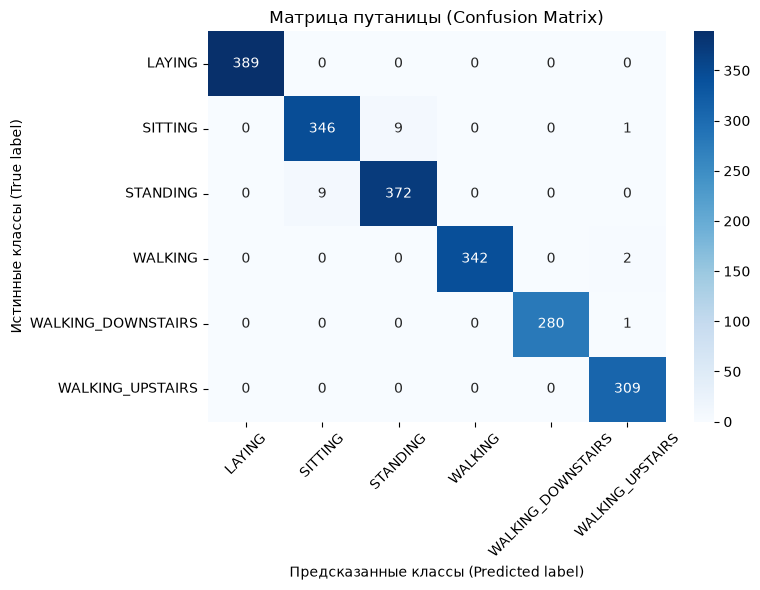

In [7]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Сетка параметров (не берем слишком огромные значения, чтобы код не работал часами)
# В реальности max_features для 561 признака можно перебирать от 4 до, скажем, 20.
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_features': [4, 10]
}

# Инициализируем базовую модель
gb_base = GradientBoostingClassifier(random_state=42)

# Настраиваем GridSearchCV
# cv=3 (3-фолдовая кросс-валидация) для экономии времени
# scoring='accuracy' (по умолчанию), n_jobs=-1 для использования всех ядер
grid_search = GridSearchCV(estimator=gb_base, param_grid=param_grid, 
                           cv=3, scoring='accuracy', n_jobs=-1, verbose=1)

print("Запуск GridSearchCV (это может занять несколько минут)...")
grid_search.fit(X_train, y_train)

# 1. Анализ лучших параметров
print("\n--- Лучшие параметры модели ---")
print(grid_search.best_params_)
print(f"Лучшая точность на кросс-валидации: {grid_search.best_score_:.4f}")

# Берем лучшую модель
best_gb = grid_search.best_estimator_

# 2. Оценка на тестовой выборке и метрики ошибок
y_pred_best = best_gb.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_best)
print(f"\nТочность лучшей модели на тестовой выборке: {test_acc:.4f}")

print("\n--- Отчет о классификации (Classification Report) ---")
# target_names берем из LabelEncoder (le.classes_)
print(classification_report(y_test, y_pred_best, target_names=le.classes_))

# 3. Построение и анализ матрицы путаницы
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Матрица путаницы (Confusion Matrix)')
plt.ylabel('Истинные классы (True label)')
plt.xlabel('Предсказанные классы (Predicted label)')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Показатели ошибок. Отчет о классификации особенно удобен в случаях с несколькими классами.

Матрица путаницы. Обратите внимание, что модель с градиентным бустингом испытывает небольшие затруднения при различении классов активности 1 и 2.

## Вопрос 5

* Создайте модель AdaBoost и подстройте её с помощью поиска по сетке, аналогично вопросу 4. Попробуйте использовать различные значения оценщика в диапазоне от 100 до 200.
* Сравните погрешности модели AdaBoost с погрешностями модели GradientBoostedClassifier.

**ПРИМЕЧАНИЕ:** Установка параметра `max_features=4` в классификаторе на основе дерева решений, используемом в качестве базового классификатора для AdaBoost, повысит скорость сходимости.

Запуск GridSearchCV для AdaBoost...
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Лучшие параметры AdaBoost: {'learning_rate': 0.5, 'n_estimators': 100}
Точность AdaBoost на тесте: 0.8019
Точность Gradient Boosting (из Вопроса 4): 0.9893

--- Отчет о классификации: AdaBoost ---
                    precision    recall  f1-score   support

            LAYING       0.84      0.84      0.84       389
           SITTING       0.70      0.68      0.69       356
          STANDING       0.75      0.76      0.75       381
           WALKING       0.88      0.90      0.89       344
WALKING_DOWNSTAIRS       0.81      0.86      0.84       281
  WALKING_UPSTAIRS       0.84      0.78      0.81       309

          accuracy                           0.80      2060
         macro avg       0.80      0.80      0.80      2060
      weighted avg       0.80      0.80      0.80      2060



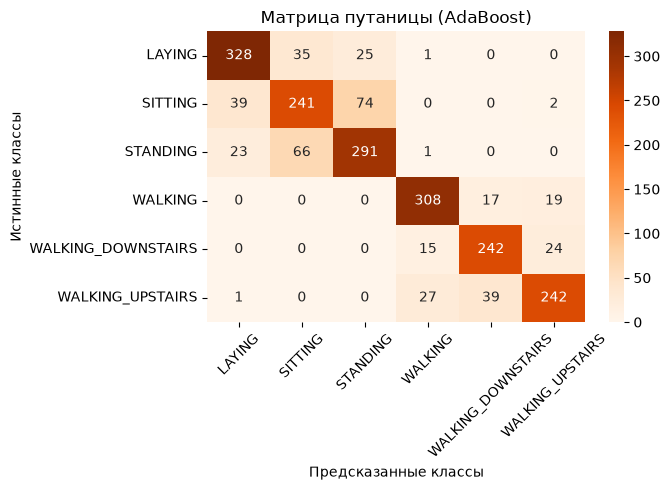

In [8]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Настройка базового классификатора (дерево решений)
# Как указано в примечании, ставим max_features=4 для ускорения
base_tree = DecisionTreeClassifier(max_features=4, random_state=42)

# 2. Сетка параметров для AdaBoost
param_grid_ada = {
    'n_estimators': [100, 150, 200],
    'learning_rate': [0.5, 1.0] # В AdaBoost скорость обучения по умолчанию 1.0
}

# 3. Поиск по сетке
ada_base = AdaBoostClassifier(estimator=base_tree, random_state=42)
grid_search_ada = GridSearchCV(estimator=ada_base, param_grid=param_grid_ada, 
                               cv=3, scoring='accuracy', n_jobs=-1, verbose=1)

print("Запуск GridSearchCV для AdaBoost...")
grid_search_ada.fit(X_train, y_train)

best_ada = grid_search_ada.best_estimator_
print(f"Лучшие параметры AdaBoost: {grid_search_ada.best_params_}")

# 4. Предсказания и анализ
y_pred_ada = best_ada.predict(X_test)
acc_ada = accuracy_score(y_test, y_pred_ada)
print(f"Точность AdaBoost на тесте: {acc_ada:.4f}")

# Для сравнения возьмем лучшую модель Gradient Boosting из Вопроса 4
y_pred_gb = best_gb.predict(X_test) 
acc_gb = accuracy_score(y_test, y_pred_gb)
print(f"Точность Gradient Boosting (из Вопроса 4): {acc_gb:.4f}\n")

print("--- Отчет о классификации: AdaBoost ---")
print(classification_report(y_test, y_pred_ada, target_names=le.classes_))

# Матрица путаницы для AdaBoost
cm_ada = confusion_matrix(y_test, y_pred_ada)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_ada, annot=True, fmt='d', cmap='Oranges', 
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Матрица путаницы (AdaBoost)')
plt.ylabel('Истинные классы')
plt.xlabel('Предсказанные классы')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Лучшая модель.

Показатели ошибок. Обратите внимание, что проблемы с классами 1 и 2, по-видимому, усугубились и теперь затрагивают также класс 0. Также обратите внимание на другие проблемы, связанные с классами 3–5. Алгоритм AdaBoost очень чувствителен к выбросам, поэтому именно в этом может заключаться причина проблемы.

## Вопрос 6

* Постройте модель логистической регрессии с регуляризацией. Это может быть аналог модели, которая хорошо себя показала в упражнениях 4-й недели.
* Используя `VotingClassifier`, постройте модель логистической регрессии вместе с моделью GratientBoostedClassifier или AdaBoost (или обеими) из вопросов 4 и 5.
* Определите ошибку, как и ранее, и сравните результаты с соответствующими моделями с градиентным бустингом.
* Постройте матрицу путаницы для лучшей модели, созданной в этом наборе упражнений.

Точность Logistic Regression: 0.9864

--- Отчет о классификации: Logistic Regression ---
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       389
           SITTING       0.97      0.96      0.96       356
          STANDING       0.97      0.97      0.97       381
           WALKING       0.99      1.00      1.00       344
WALKING_DOWNSTAIRS       1.00      1.00      1.00       281
  WALKING_UPSTAIRS       1.00      0.99      0.99       309

          accuracy                           0.99      2060
         macro avg       0.99      0.99      0.99      2060
      weighted avg       0.99      0.99      0.99      2060


Точность Voting Classifier: 0.9927

--- Отчет о классификации: Voting Classifier ---
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       389
           SITTING       0.98      0.98      0.98       356
          STANDING       0.98      0.98  

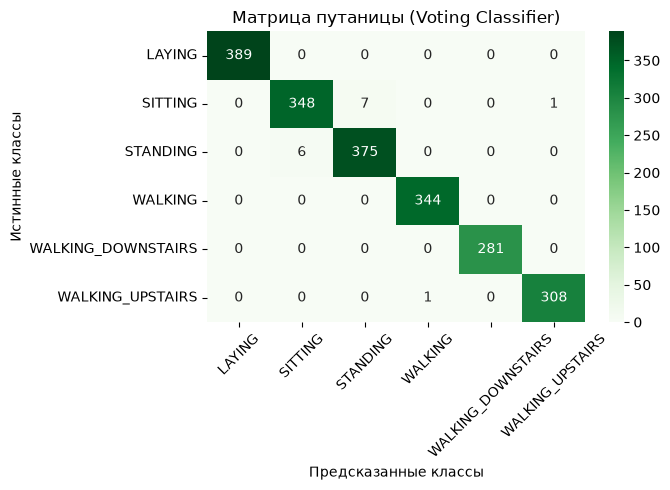


Точность Stacking Classifier: 0.9883


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.metrics import accuracy_score

# ==========================================
# 1. Логистическая регрессия с регуляризацией
# ==========================================
# C = 1/lambda. Уменьшая C, мы увеличиваем регуляризацию (L2 по умолчанию).
# max_iter увеличен, чтобы алгоритм успел сойтись на 561 признаке.
log_reg = LogisticRegression(C=1.0, max_iter=2000, random_state=42, n_jobs=-1)
log_reg.fit(X_train, y_train)
y_pred_lr = log_reg.predict(X_test)
acc_lr = accuracy_score(y_test, y_pred_lr)

print(f"Точность Logistic Regression: {acc_lr:.4f}")
print("\n--- Отчет о классификации: Logistic Regression ---")
print(classification_report(y_test, y_pred_lr, target_names=le.classes_))

# ==========================================
# 2. Ансамбль VotingClassifier (Голосование)
# ==========================================
# Берем лучшие модели из предыдущих пунктов
voting_clf = VotingClassifier(
    estimators=[
        ('lr', log_reg),
        ('gb', best_gb) # Модель из Вопроса 4
    ],
    voting='soft' # 'soft' использует вероятности, обычно работает лучше, чем 'hard'
)

voting_clf.fit(X_train, y_train)
y_pred_vote = voting_clf.predict(X_test)
acc_vote = accuracy_score(y_test, y_pred_vote)

print(f"\nТочность Voting Classifier: {acc_vote:.4f}")
print("\n--- Отчет о классификации: Voting Classifier ---")
print(classification_report(y_test, y_pred_vote, target_names=le.classes_))

# Построение матрицы путаницы для ансамбля (он обычно лучший)
cm_vote = confusion_matrix(y_test, y_pred_vote)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_vote, annot=True, fmt='d', cmap='Greens', 
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Матрица путаницы (Voting Classifier)')
plt.ylabel('Истинные классы')
plt.xlabel('Предсказанные классы')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ==========================================
# 3. Многоуровневая модель (Stacking)
# ==========================================
# Базовые модели
estimators = [
    ('lr', LogisticRegression(C=1.0, max_iter=2000)),
    ('gb', GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_features=4, random_state=42))
]

# Мета-модель (которая учится исправлять ошибки базовых)
meta_model = LogisticRegression(max_iter=1000)

stack_clf = StackingClassifier(
    estimators=estimators, 
    final_estimator=meta_model,
    cv=3 # Для обучения мета-модели используем 3-фолдовую валидацию
)

stack_clf.fit(X_train, y_train)
y_pred_stack = stack_clf.predict(X_test)
acc_stack = accuracy_score(y_test, y_pred_stack)

print(f"\nТочность Stacking Classifier: {acc_stack:.4f}")

Проверьте ошибки и матрицу путаницы для модели логистической регрессии.

А теперь — многоуровневая модель (stacked model).

Наконец, рассмотрим ошибку классификатора при голосовании. Здесь мы показываем немного лучшие результаты, чем при использовании либо логистической регрессии, либо градиентных бустеров по отдельности. Однако тот факт, что логистическая регрессия демонстрирует почти такие же результаты, как и градиентные бустеры, служит важным напоминанием о том, что сначала следует пробовать самую простую модель. В некоторых случаях её эффективности будет вполне достаточно.